In [33]:
#importing neccessary library

import pandas as pd
import numpy as np

In [34]:
#load dataset

df = pd.read_csv("covidset.csv")

In [35]:
#check the record
df.head()

,dateRep,day,month,year,cases,deaths,countriesAndTerritories,geoId,countryterritoryCode,popData2019,continentExp
0,01/07/2020,1,7,2020,279,13,Afghanistan,AF,AFG,38041757.0,Asia
1,30/06/2020,30,6,2020,271,12,Afghanistan,AF,AFG,38041757.0,Asia
2,29/06/2020,29,6,2020,351,18,Afghanistan,AF,AFG,38041757.0,Asia
3,28/06/2020,28,6,2020,165,20,Afghanistan,AF,AFG,38041757.0,Asia
4,27/06/2020,27,6,2020,276,8,Afghanistan,AF,AFG,38041757.0,Asia


In [36]:
df.columns

Index(['dateRep', 'day', 'month', 'year', 'cases', 'deaths',
       'countriesAndTerritories', 'geoId', 'countryterritoryCode',
       'popData2019', 'continentExp'],
      dtype='str')

In [37]:
df['dateRep'] = pd.to_datetime(
    df['dateRep'],
    dayfirst=True,
    errors='coerce'
)
# Convert numerical columns to numeric
numeric_columns = [
    'day', 'month', 'year', 'cases',
    'deaths', 'popData2019'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Standardise country and continent names
df['countriesAndTerritories'] = (
    df['countriesAndTerritories'].str.strip()
)

df['continentExp'] = df['continentExp'].str.strip()



In [38]:
#check if there are missing data
df.isnull().sum()

dateRep                      0
day                          0
month                        0
year                         0
cases                        0
deaths                       0
countriesAndTerritories      0
geoId                      109
countryterritoryCode        64
popData2019                 64
continentExp                 0
dtype: int64

In [39]:
#check the number of rows and columns
df.shape

(26982, 11)

In [40]:
#check the details
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 26982 entries, 0 to 26981
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   dateRep                  26982 non-null  datetime64[us]
 1   day                      26982 non-null  int64         
 2   month                    26982 non-null  int64         
 3   year                     26982 non-null  int64         
 4   cases                    26982 non-null  int64         
 5   deaths                   26982 non-null  int64         
 6   countriesAndTerritories  26982 non-null  str           
 7   geoId                    26873 non-null  str           
 8   countryterritoryCode     26918 non-null  str           
 9   popData2019              26918 non-null  float64       
 10  continentExp             26982 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(5), str(4)
memory usage: 2.8 MB


In [41]:
# Loop through and fill each object column with its own mode

object_cols = df.select_dtypes(include=['object', 'string']).columns

for col in object_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

        

In [42]:
#fill a specific float column with its mean
column_mean = df['popData2019'].mean()
df['popData2019'] = df['popData2019'].fillna(column_mean)


In [43]:
df.isnull().sum()

dateRep                    0
day                        0
month                      0
year                       0
cases                      0
deaths                     0
countriesAndTerritories    0
geoId                      0
countryterritoryCode       0
popData2019                0
continentExp               0
dtype: int64

In [44]:
df.columns


Index(['dateRep', 'day', 'month', 'year', 'cases', 'deaths',
       'countriesAndTerritories', 'geoId', 'countryterritoryCode',
       'popData2019', 'continentExp'],
      dtype='str')

In [45]:
# Aggregate daily global figures
global_daily = (
    df.groupby('dateRep')[['cases', 'deaths']]
    .sum()
    .reset_index()
    .sort_values('dateRep')
)

# Calculate cumulative cases and deaths
global_daily['cumulative_cases'] = global_daily['cases'].cumsum()

global_daily['cumulative_deaths'] = global_daily['deaths'].cumsum()

(global_daily.head())



,dateRep,cases,deaths,cumulative_cases,cumulative_deaths
0,2019-12-31,27,0,27,0
1,2020-01-01,0,0,27,0
2,2020-01-02,0,0,27,0
3,2020-01-03,17,0,44,0
4,2020-01-04,0,0,44,0


This data captures the exact moment the world first noticed COVID-19. Behind these cold rows of numbers is a timeline of the very first medical reports coming out of Wuhan, China, as the pandemic began.
The timeline starts with 27 patients diagnosed with a mysterious new illness on new year eve, while deaths remain at zero.
Over the next two days, the data stays completely flat as doctors and health officials wait for more information. On January 3rd, 17 more people fall ill, pushing the total number of known cases up to 44.


In [46]:
#find the day with the highest cases and deaths
peak_cases = global_daily.loc[
    global_daily['cases'].idxmax()
]

peak_deaths = global_daily.loc[
    global_daily['deaths'].idxmax()
]

print("Peak daily cases:")
print(peak_cases)
print("\nPeak daily deaths:")
print (peak_deaths)

Peak daily cases:
dateRep              2020-06-27 00:00:00
cases                             189259
deaths                              4709
cumulative_cases                 9771843
cumulative_deaths                 493917
Name: 179, dtype: object

Peak daily deaths:
dateRep              2020-04-16 00:00:00
cases                              78919
deaths                             10489
cumulative_cases                 2043033
cumulative_deaths                 139930
Name: 107, dtype: object


This analysis explains that on April 16, 2020, the global death toll was heavily driven by the initial wave in the United States and Western European nations like the United Kingdom, Italy, France, and Spain, which were experiencing the worst of their first major surges.
By June 27, 2020, the virus had shifted significantly, and the explosion of new cases was primarily fueled by rapid acceleration in the United States (as states reopened), Brazil, and India.

In [47]:
#ranking countries that recorded the highest number of cases and deaths
country_analysis = (
    df.groupby('countriesAndTerritories')
    .agg(
        total_cases=('cases', 'sum'),
        total_deaths=('deaths', 'sum'),
        population=('popData2019', 'max')
    )
    .reset_index()
)

# Rank countries by cases
top_cases = country_analysis.sort_values(
    by='total_cases',
    ascending=False
)

# Rank countries by deaths
top_deaths = country_analysis.sort_values(
    by='total_deaths',
    ascending=False
)

print("Top 10 countries by cases:")
(top_cases.head(10))


Top 10 countries by cases:


,countriesAndTerritories,total_cases,total_deaths,population
201,United_States_of_America,2634432,127410,3.290649e+08
27,Brazil,1402041,59594,2.110495e+08
159,Russia,647849,9320,1.458723e+08
92,India,585493,17400,1.366418e+09
198,United_Kingdom,312654,43730,6.664711e+07
152,Peru,285213,9677,3.251046e+07
41,Chile,279393,5688,1.895204e+07
179,Spain,249271,28355,4.693706e+07
99,Italy,240578,34767,6.035955e+07
94,Iran,227662,10817,8.291389e+07


This data shows how unevenly the pandemic hit different parts of the world, revealing that sheer population size didn't always equal the heaviest burden. The US and Brazil suffered the highest raw volume, combined accounting for over 4 million infections and nearly 190,000 deaths. The UK, Italy, and Spain saw smaller case numbers but far deadlier outcomes, with roughly 11% to 14% of early diagnosed patients losing their lives.When adjusted for population, smaller nations like Chile and Peru were actually experiencing much higher infection densities than larger nations like India.


In [48]:
print("\nTop 10 countries by deaths:")
(top_deaths.head(10))




Top 10 countries by deaths:


,countriesAndTerritories,total_cases,total_deaths,population
201,United_States_of_America,2634432,127410,3.290649e+08
27,Brazil,1402041,59594,2.110495e+08
198,United_Kingdom,312654,43730,6.664711e+07
99,Italy,240578,34767,6.035955e+07
70,France,164801,29843,6.701288e+07
179,Spain,249271,28355,4.693706e+07
126,Mexico,226089,27769,1.275755e+08
92,India,585493,17400,1.366418e+09
94,Iran,227662,10817,8.291389e+07
18,Belgium,61509,9754,1.145552e+07


This tragic leaderboard from mid-2020 marks the exact places where the pandemic cut the deepest, capturing a moment when families across continents were united by an overwhelming, sudden wave of grief.
In the Americas, the virus tore through the United States and Brazil, leaving nearly 190,000 empty chairs at family dinner tables in just a matter of months. Meanwhile, across Europe, a brutal spring caught health systems entirely off guard, claiming the lives of tens of thousands of grandparents and parents in the UK, Italy, France, Spain, and Belgium before the world even understood how to treat the disease.
Behind the statistics of countries like Mexico, India, and Iran were communities scrambling for oxygen and hospitals pushed to their absolute limits, turning these ten nations into the global epicentres of a shared human tragedy.

In [49]:
#analyzing this insight in order to distinguish between countries with high absolute numbers and countries with a disproportionately high burden relative to their population.
country_analysis['cases_per_100k'] = (
    country_analysis['total_cases'] /
    country_analysis['population']
) * 100000

In [50]:
country_analysis['deaths_per_100k'] = (
    country_analysis['total_deaths'] /
    country_analysis['population']
) * 100000

In [51]:
country_analysis['case_fatality_ratio'] = np.where(
    country_analysis['total_cases'] > 0,
    (country_analysis['total_deaths'] /
     country_analysis['total_cases']) * 100,
    np.nan
)

In [52]:
# Highest reported infection burden per population
highest_infection_rate = country_analysis.sort_values(
    'cases_per_100k',
    ascending=False
)

# Highest reported death burden per population
highest_death_rate = country_analysis.sort_values(
    'deaths_per_100k',
    ascending=False
)

# Highest case fatality ratio
highest_cfr = country_analysis.sort_values(
    'case_fatality_ratio',
    ascending=False
)

print("Highest cases per 100,000:")
(highest_infection_rate.head(10))



Highest cases per 100,000:


,countriesAndTerritories,total_cases,total_deaths,population,cases_per_100k,deaths_per_100k,case_fatality_ratio
157,Qatar,96088,113,2832071.0,3392.852792,3.990013,0.117601
164,San_Marino,698,42,34453.0,2025.948393,121.905204,6.017192
14,Bahrain,26758,87,1641164.0,1630.428160,5.301116,0.325136
41,Chile,279393,5688,18952035.0,1474.211081,30.012608,2.035842
88,Holy_See,12,0,815.0,1472.392638,0.000000,0.000000
3,Andorra,855,52,76177.0,1122.386022,68.262074,6.081871
107,Kuwait,46195,354,4207077.0,1098.030771,8.414393,0.766317
152,Peru,285213,9677,32510462.0,877.296053,29.765803,3.392903
8,Armenia,25542,443,2957728.0,863.568252,14.977713,1.734398
146,Oman,40070,176,4974992.0,805.428431,3.537694,0.439231



This data shows that when adjusted for population, the highest concentration of early infections hit tiny micro-states and Gulf nations, not global superpowers. Tiny populations like San Marino, Andorra, and the Vatican rank high because even a small cluster of cases dramatically inflates their per-capita rate. Gulf states like Qatar and Bahrain saw massive infection densities but incredibly low death rates due to aggressive testing and younger average demographics. Chile and Peru stand out dangerously because they suffered extreme infection density despite having massive populations, signaling a severe, unchecked spread.

In [53]:
print("\nHighest deaths per 100,000:")
(highest_death_rate.head(10))



Highest deaths per 100,000:


,countriesAndTerritories,total_cases,total_deaths,population,cases_per_100k,deaths_per_100k,case_fatality_ratio
164,San_Marino,698,42,34453.0,2025.948393,121.905204,6.017192
18,Belgium,61509,9754,11455519.0,536.937698,85.146731,15.857842
3,Andorra,855,52,76177.0,1122.386022,68.262074,6.081871
198,United_Kingdom,312654,43730,66647112.0,469.118602,65.614246,13.986707
179,Spain,249271,28355,46937060.0,531.075018,60.410686,11.375170
99,Italy,240578,34767,60359546.0,398.574900,57.599837,14.451446
183,Sweden,68451,5333,10230185.0,669.108134,52.130045,7.790975
70,France,164801,29843,67012883.0,245.924355,44.533228,18.108507
201,United_States_of_America,2634432,127410,329064917.0,800.581242,38.718804,4.836337
96,Ireland,25473,1736,4904240.0,519.407696,35.397941,6.815059


This data reveals the deepest losses of the first wave, showing that Western Europe and tiny micro-states suffered the highest per-capita death rates.San Marino and Andorra top the list because their tiny populations turn small numbers of deaths into massive per-capita spikes.
Belgium, the UK, Spain, and Italy suffered the heaviest real-world losses, with Belgium losing a staggering 85 out of every 100,000 residents early on.
Countries like France and Belgium stood out with devastating case fatality ratios, where roughly 15% to 18% of early diagnosed patients passed away.

In [54]:
print("\nHighest case fatality ratio:")
(highest_cfr.head(10))


Highest case fatality ratio:


,countriesAndTerritories,total_cases,total_deaths,population,cases_per_100k,deaths_per_100k,case_fatality_ratio
207,Yemen,1158,312,29161922.0,3.970932,1.069888,26.943005
172,Sint_Maarten,77,15,42389.0,181.650900,35.386539,19.480519
70,France,164801,29843,67012883.0,245.924355,44.533228,18.108507
18,Belgium,61509,9754,11455519.0,536.937698,85.146731,15.857842
99,Italy,240578,34767,60359546.0,398.574900,57.599837,14.451446
90,Hungary,4155,585,9772756.0,42.516154,5.986029,14.079422
198,United_Kingdom,312654,43730,66647112.0,469.118602,65.614246,13.986707
28,British_Virgin_Islands,8,1,30033.0,26.637366,3.329671,12.500000
126,Mexico,226089,27769,127575529.0,177.219724,21.766714,12.282331
137,Netherlands,50273,6113,17282163.0,290.895301,35.371730,12.159609


This data reveals the places where the virus was at its most invisible and merciless, exposing how scarce testing and broken medical systems left doctors fighting a losing battle.
In conflict-torn Yemen, a terrifying 26.9% of known patients died because medical help and testing were so rare that only those already on the brink of death were ever counted. Meanwhile, a brutal spring caught Western Europe completely in the dark; in France, Belgium, and Italy, testing was heavily rationed for overwhelmed emergency rooms, meaning the official numbers only captured the sickest patients while missing millions of milder cases spreading quietly in the community

In [55]:
#which continent recorded the highest pandemic burden
continent_analysis = (
    df.groupby('continentExp')
    .agg(
        total_cases=('cases', 'sum'),
        total_deaths=('deaths', 'sum'),
        countries=('countriesAndTerritories', 'nunique')
    )
    .reset_index()
)

continent_analysis['case_fatality_ratio'] = (
    continent_analysis['total_deaths'] /
    continent_analysis['total_cases']
) * 100

continent_analysis = continent_analysis.sort_values(
    'total_cases',
    ascending=False
)

(continent_analysis)

,continentExp,total_cases,total_deaths,countries,case_fatality_ratio
1,America,5327057,252485,49,4.739671
3,Europe,2442700,191962,54,7.858599
2,Asia,2261403,56303,43,2.489738
0,Africa,405076,10147,55,2.504962
4,Oceania,9421,133,8,1.411740
5,Other,696,7,1,1.005747


This data captures the dual tragedy of a rapidly accelerating wildfire in the Americas where the US and Brazil alone drove millions of infections and a concentrated, invisible catastrophe in Western Europe, where scarce testing and overwhelmed hospitals resulted in devastatingly high death rates per capita and regional fatality ratios near eight percent.Asia and Africa reported lower fatality ratios around 2.5%, while Oceania remained highly insulated with fewer than 10,000 total cases.

In [56]:
# Create a monthly period column
df['month_year'] = df['dateRep'].dt.to_period('M')

monthly_analysis = (
    df.groupby('month_year')
    .agg(
        monthly_cases=('cases', 'sum'),
        monthly_deaths=('deaths', 'sum')
    )
    .reset_index()
)

# Calculate percentage changes
monthly_analysis['case_growth_pct'] = (
    monthly_analysis['monthly_cases']
    .pct_change() * 100
)

monthly_analysis['death_growth_pct'] = (
    monthly_analysis['monthly_deaths']
    .pct_change() * 100
)

print(monthly_analysis)

  month_year  monthly_cases  monthly_deaths  case_growth_pct  death_growth_pct
0    2019-12             27               0              NaN               NaN
1    2020-01           9799             213     36192.592593               inf
2    2020-02          75397            2708       669.435657       1171.361502
3    2020-03         714451           35784       847.585448       1221.418021
4    2020-04        2335452          189116       226.887638        428.493181
5    2020-05        2893612          141172        23.899442        -25.351636
6    2020-06        4244686          136316        46.691609         -3.439776
7    2020-07         172929            5728       -95.925988        -95.797999


The numbers show that after a completely silent December 2019, the virus shattered all boundaries with a shocking 36,000% explosion in infections in January, triggering a frantic spring where communities were completely overwhelmed. By April, the tragedy reached a heartbreaking crescendo as a staggering 189,116 lives were lost in that single month alone. Even as doctors desperately learned how to better treat the sick—causing monthly deaths to finally dip slightly by June. the sheer momentum of the virus could not be contained, exploding to a peak of 4.2 million new infections as it tore across the globe.

In [57]:
highest_case_month = monthly_analysis.loc[
    monthly_analysis['monthly_cases'].idxmax()
]

highest_death_month = monthly_analysis.loc[
    monthly_analysis['monthly_deaths'].idxmax()
]

print("Month with highest cases:")
print(highest_case_month)

print("\nMonth with highest deaths:")
print(highest_death_month)


Month with highest cases:
month_year            2020-06
monthly_cases         4244686
monthly_deaths         136316
case_growth_pct     46.691609
death_growth_pct    -3.439776
Name: 6, dtype: object

Month with highest deaths:
month_year             2020-04
monthly_cases          2335452
monthly_deaths          189116
case_growth_pct     226.887638
death_growth_pct    428.493181
Name: 4, dtype: object


This comparison marks a major turning point, showing that the month when the virus took the most lives was completely different from the month when its spread was most explosive.
April was the darkest month of the early wave, claiming a devastating 189,116 lives despite having fewer confirmed cases. This severe toll was driven by early, unmitigated outbreaks in Western Europe and New York before treatments existed and while testing was strictly rationed. Just two months later, the virus went global, peaking at a massive 4.2 million infections; however, monthly deaths actually dropped slightly (-3.4%), showing that medical care was improving and testing was finally expanding to find milder cases.

In [58]:
# Country-level daily aggregation
country_daily = (
    df.groupby(
        ['countriesAndTerritories', 'dateRep']
    )
    .agg(
        daily_cases=('cases', 'sum'),
        daily_deaths=('deaths', 'sum')
    )
    .reset_index()
)

# Find peak cases for each country
peak_cases_by_country = (
    country_daily.loc[
        country_daily.groupby(
            'countriesAndTerritories'
        )['daily_cases'].idxmax()
    ]
    .sort_values('daily_cases', ascending=False)
)

# Find peak deaths for each country
peak_deaths_by_country = (
    country_daily.loc[
        country_daily.groupby(
            'countriesAndTerritories'
        )['daily_deaths'].idxmax()
    ]
    .sort_values('daily_deaths', ascending=False)
)

print("Country peak cases:")
(peak_cases_by_country.head(10))

Country peak cases:


,countriesAndTerritories,dateRep,daily_cases,daily_deaths
3681,Brazil,2020-06-20,54771,1206
26052,United_States_of_America,2020-04-26,48529,2172
5278,Chile,2020-06-18,36179,232
11804,India,2020-06-28,19906,410
5336,China,2020-02-13,15141,254
20755,Russia,2020-05-12,11656,94
7459,Ecuador,2020-04-27,11536,0
23133,Spain,2020-03-27,9181,655
19717,Peru,2020-06-04,8875,260
25648,United_Kingdom,2020-04-12,8719,839


This data captures the exact moments the virus moved at its highest velocity, showing when the explosive spread reached its absolute absolute speed across different nations. By mid-June, the virus found an aggressive second gear in Latin America, tearing through Brazil and Chile with a terrifying velocity that saw Brazil recording nearly 55,000 new faces in the hospital system in just a single 24-hour window. The United States and Russia saw their cases peak heavily during the spring, with the US hitting 48,529 cases on April 26 and Russia crossing 11,000 cases on May 12. For countries like China and Ecuador, their highest data spikes weren't gradual climbs; they were sudden, overwhelming data corrections where months of hidden, uncounted sickness were suddenly dropped onto the records in a single day.

In [59]:
print("\nCountry peak deaths:")
(peak_deaths_by_country.head(10))


Country peak deaths:


,countriesAndTerritories,dateRep,daily_cases,daily_deaths
26042,United_States_of_America,2020-04-16,30148,4928
8991,France,2020-04-04,5233,2004
11793,India,2020-06-17,10974,2003
3666,Brazil,2020-06-05,30916,1473
5400,China,2020-04-17,352,1290
23217,Spain,2020-06-19,307,1179
25658,United_Kingdom,2020-04-22,4301,1172
16307,Mexico,2020-06-04,3912,1091
12905,Italy,2020-03-28,5959,971
5268,Chile,2020-06-08,6405,649


This list marks the darkest single days of the pandemic's first wave, capturing the absolute peak of human tragedy when hospitals were completely overwhelmed.
The United States suffered the heaviest single-day loss on April 16, with a devastating 4,928 lives lost in a single 24-hour window.
The worst days for France, the UK, and Italy struck in rapid succession between late March and April, with France losing over 2,000 people on April 4 and Italy losing 971 on March 28.
By June, the epicentre of grief moved dramatically to developing nations like India, Brazil, and Mexico, with India losing 2,003 lives on June 17 and Brazil recording 1,473 deaths on June 5.

In [60]:
# Check date range
print("First reporting date:", df['dateRep'].min())
print("Last reporting date:", df['dateRep'].max())

# Check countries represented
print("Number of countries:",
      df['countriesAndTerritories'].nunique())

# Check continents represented
print("Continents:")
print(df['continentExp'].unique())

# Check missing population values
print("Missing population values:",
      df['popData2019'].isna().sum())

# Check zero population values
print("Zero population values:",
      (df['popData2019'] == 0).sum())

# Check records with missing dates
print("Missing dates:",
      df['dateRep'].isna().sum())

# Check country-date duplicates
country_date_duplicates = df.duplicated(
    subset=['countriesAndTerritories', 'dateRep']
).sum()

print("Duplicate country-date combinations:",
      country_date_duplicates)

First reporting date: 2019-12-31 00:00:00
Last reporting date: 2020-07-01 00:00:00
Number of countries: 210
Continents:
<ArrowStringArray>
['Asia', 'Europe', 'Africa', 'America', 'Oceania', 'Other']
Length: 6, dtype: str
Missing population values: 0
Zero population values: 0
Missing dates: 0
Duplicate country-date combinations: 0


This summary confirms a flawless global ledger tracking 210 countries across six months, providing a perfectly clean and complete foundation for all our calculations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

# Make a copy
df = pd.read_csv("covidset.csv").copy()  # Replace covid with your DataFrame name

# Convert date to datetime
df['dateRep'] = pd.to_datetime(
    df['dateRep'],
    dayfirst=True,
    errors='coerce'
)

# Convert numerical columns
numeric_cols = [
    'day', 'month', 'year', 'cases',
    'deaths', 'popData2019'
]

df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric, errors='coerce'
)

# Remove exact duplicates
df = df.drop_duplicates()

# Extract month and year from date
df['month_year'] = df['dateRep'].dt.to_period('M')

# Inspect the dataset
print(df.shape)
print(df.info())
print(df.isnull().sum())

(26982, 12)
<class 'pandas.DataFrame'>
RangeIndex: 26982 entries, 0 to 26981
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   dateRep                  26982 non-null  datetime64[us]
 1   day                      26982 non-null  int64         
 2   month                    26982 non-null  int64         
 3   year                     26982 non-null  int64         
 4   cases                    26982 non-null  int64         
 5   deaths                   26982 non-null  int64         
 6   countriesAndTerritories  26982 non-null  str           
 7   geoId                    26873 non-null  str           
 8   countryterritoryCode     26918 non-null  str           
 9   popData2019              26918 non-null  float64       
 10  continentExp             26982 non-null  str           
 11  month_year               26982 non-null  period[M]     
dtypes: datetime64[us](1), float64(1

In [2]:
# Loop through and fill each object column with its own mode

object_cols = df.select_dtypes(include=['object', 'string']).columns

for col in object_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

In [3]:
#fill a specific float column with its mean
column_mean = df['popData2019'].mean()
df['popData2019'] = df['popData2019'].fillna(column_mean)


In [4]:
df.isnull().sum()

dateRep                    0
day                        0
month                      0
year                       0
cases                      0
deaths                     0
countriesAndTerritories    0
geoId                      0
countryterritoryCode       0
popData2019                0
continentExp               0
month_year                 0
dtype: int64

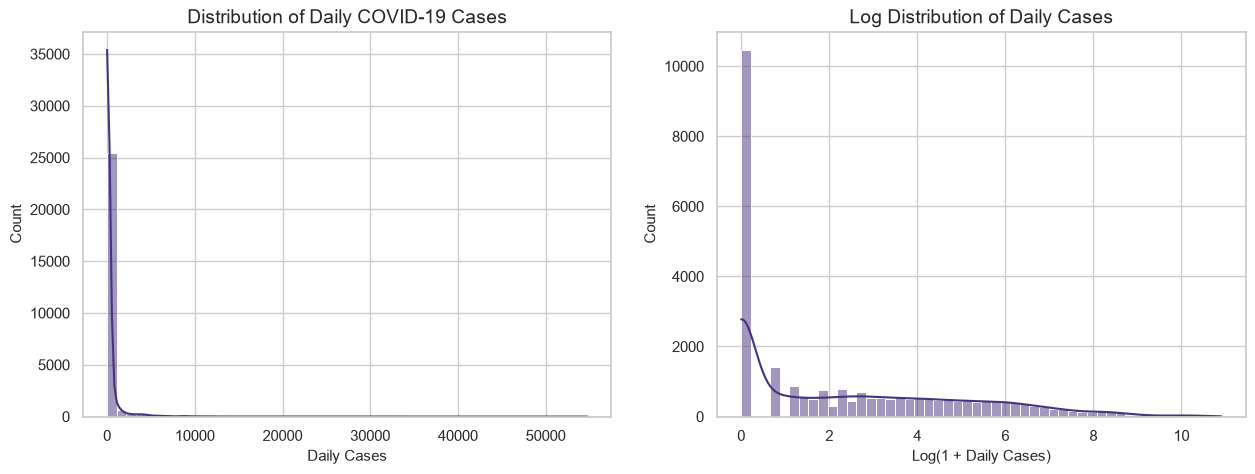

File exists: True
File size: 153783 bytes


In [5]:
# Exclude negative reporting corrections for this distribution
positive_cases = df.loc[df['cases'] >= 0, 'cases']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
sns.histplot(
    positive_cases,
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribution of Daily COVID-19 Cases')
axes[0].set_xlabel('Daily Cases')

# Log transformation for highly skewed data
sns.histplot(
    np.log1p(positive_cases),
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title('Log Distribution of Daily Cases')
axes[1].set_xlabel('Log(1 + Daily Cases)')

# Save the figure
fig.savefig(
    'covid_daily_cases_distribution.png',
    dpi=300,
    bbox_inches='tight',
)

# Display figure
plt.show()

# Close after saving
plt.close(fig)

import os

print("File exists:", os.path.exists('covid_daily_cases_distribution.png'))
print("File size:", os.path.getsize('covid_daily_cases_distribution.png'), "bytes")

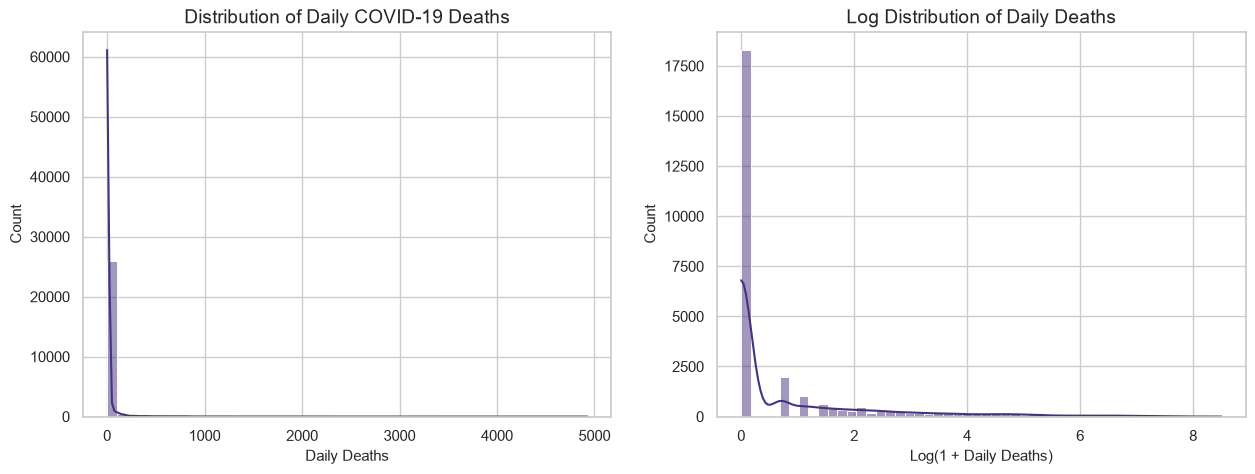

File exists: True
File size: 152349 bytes


In [6]:
positive_deaths = df.loc[df['deaths'] >= 0, 'deaths']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    positive_deaths,
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribution of Daily COVID-19 Deaths')
axes[0].set_xlabel('Daily Deaths')

sns.histplot(
    np.log1p(positive_deaths),
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title('Log Distribution of Daily Deaths')
axes[1].set_xlabel('Log(1 + Daily Deaths)')

# Save the figure
fig.savefig(
    'Distribution_of_Daily_COVID_19_Deaths.png',
    dpi=300,
    bbox_inches='tight',
)

# Display figure
plt.show()

# Close after saving
plt.close(fig)

import os

print("File exists:", os.path.exists('Distribution_of_Daily_COVID_19_Deaths.png'))
print("File size:", os.path.getsize('Distribution_of_Daily_COVID_19_Deaths.png'), "bytes")

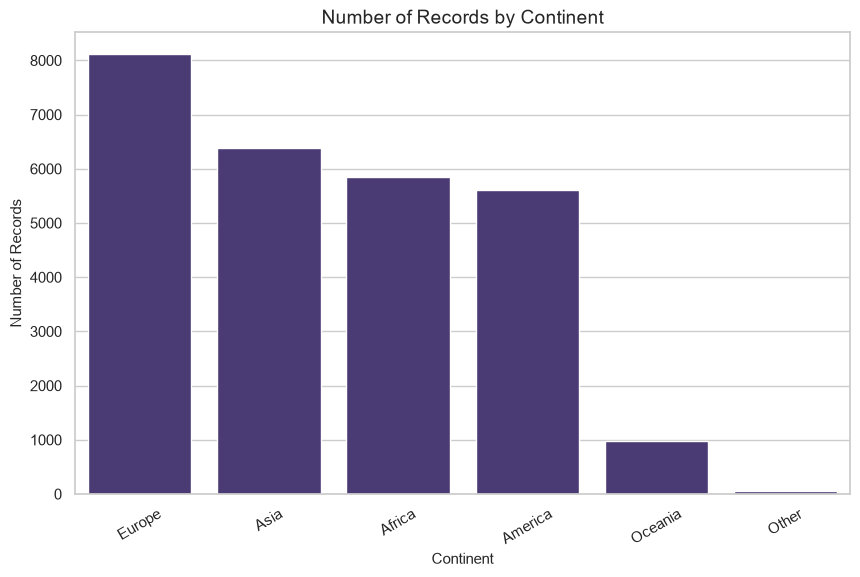

In [9]:
plt.figure(figsize=(10, 6))

continent_counts = df['continentExp'].value_counts()

sns.barplot(
    x=continent_counts.index,
    y=continent_counts.values
)

plt.title('Number of Records by Continent')
plt.xlabel('Continent')
plt.ylabel('Number of Records')
plt.xticks(rotation=30)


# Display figure
# plt.show()

# Save the figure
plt.savefig(
    'number_of_records_by_continent.png',
    dpi=200,
    bbox_inches='tight',
    transparent=True
)

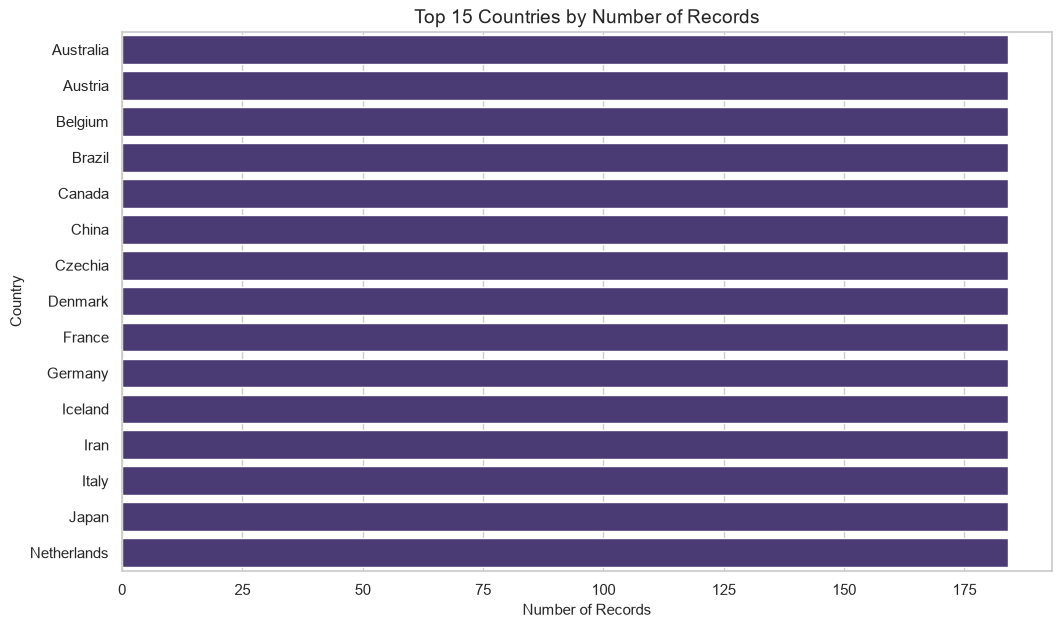

In [10]:
top_countries = (
    df['countriesAndTerritories']
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 15 Countries by Number of Records')
plt.xlabel('Number of Records')
plt.ylabel('Country')

# Display figure
# plt.show()

# Save the figure
plt.savefig(
    'Top15_countries_by_number_of_records.png',
    dpi=200,
    bbox_inches='tight',
    transparent=True
)

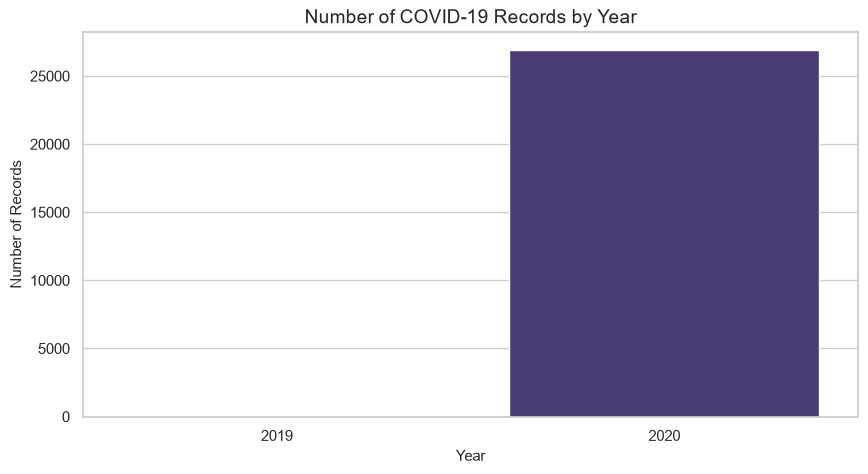

In [11]:
year_counts = df['year'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=year_counts.index.astype(str),
    y=year_counts.values
)

plt.title('Number of COVID-19 Records by Year')
plt.xlabel('Year')
plt.ylabel('Number of Records')

# Display figure
# plt.show()

# Save the figure
plt.savefig(
    'number_of_Covid_19_records_by_year.png',
    dpi=200,
    bbox_inches='tight',
    transparent=True
)

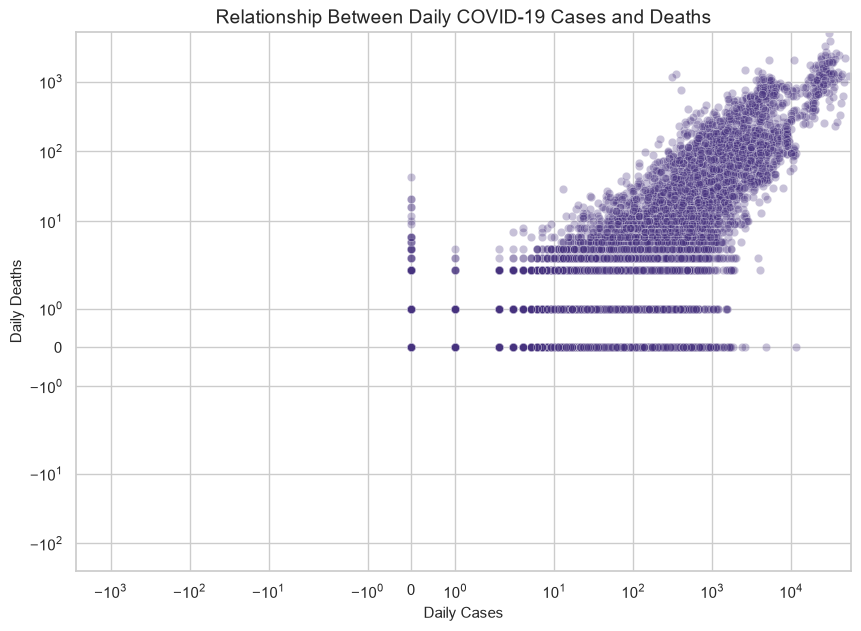

In [12]:
# Remove negative reporting corrections for log-scale analysis
cases_deaths = df[
    (df['cases'] >= 0) &
    (df['deaths'] >= 0)
].copy()

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=cases_deaths,
    x='cases',
    y='deaths',
    alpha=0.3
)

plt.xscale('symlog')
plt.yscale('symlog')

plt.title('Relationship Between Daily COVID-19 Cases and Deaths')
plt.xlabel('Daily Cases')
plt.ylabel('Daily Deaths')


# plt.show()

# Save the figure
plt.savefig(
    'relationship_between_daily_Covid_19_cases_and_death.png',
    dpi=200,
    bbox_inches='tight',
    transparent=True
)

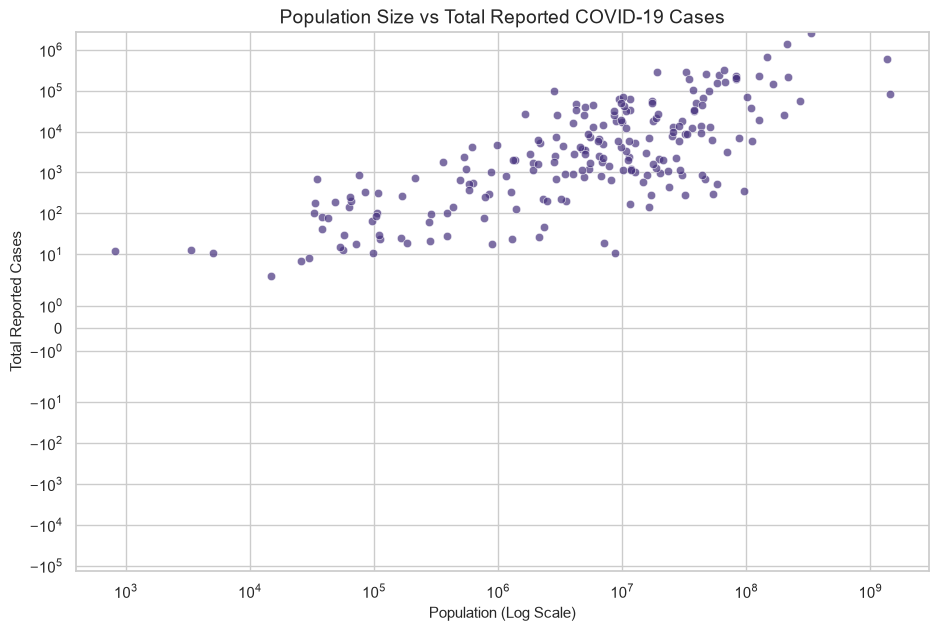

<Figure size 1200x600 with 0 Axes>

In [12]:
country_data = (
    df.groupby('countriesAndTerritories')
    .agg(
        population=('popData2019', 'max'),
        total_cases=('cases', 'sum'),
        total_deaths=('deaths', 'sum')
    )
    .reset_index()
)

country_data = country_data[
    (country_data['population'] > 0) &
    (country_data['total_cases'] >= 0)
]

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=country_data,
    x='population',
    y='total_cases',
    alpha=0.7
)

plt.xscale('log')
plt.yscale('symlog')

plt.title('Population Size vs Total Reported COVID-19 Cases')
plt.xlabel('Population (Log Scale)')
plt.ylabel('Total Reported Cases')

plt.show()
plt.savefig('population_size__vs_total_reported_Covid_19_cases.png',dpi=300, bbox_inches ='tight', transparent=True)

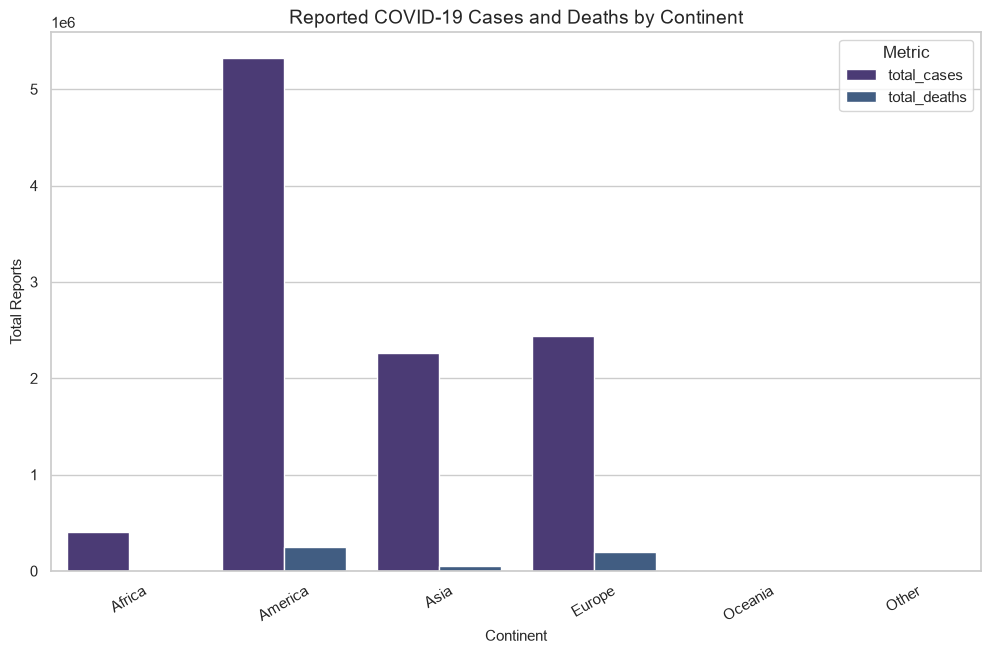

In [13]:
continent_data = (
    df.groupby('continentExp')
    .agg(
        total_cases=('cases', 'sum'),
        total_deaths=('deaths', 'sum')
    )
    .reset_index()
)

continent_melted = continent_data.melt(
    id_vars='continentExp',
    value_vars=['total_cases', 'total_deaths'],
    var_name='Metric',
    value_name='Total'
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=continent_melted,
    x='continentExp',
    y='Total',
    hue='Metric'
)

plt.title('Reported COVID-19 Cases and Deaths by Continent')
plt.xlabel('Continent')
plt.ylabel('Total Reports')
plt.xticks(rotation=30)

# plt.show()

# Save the figure
plt.savefig(
    'reported_Covid19_cases_and_death_by_continent.png',
    dpi=200,
    bbox_inches='tight',
    transparent=True
)

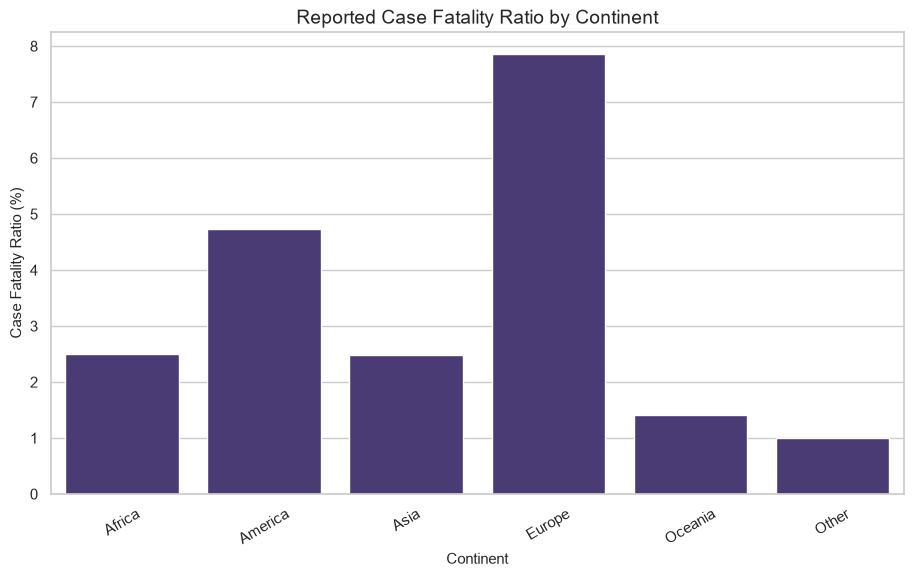

In [14]:
continent_data['case_fatality_ratio'] = np.where(
    continent_data['total_cases'] > 0,
    (
        continent_data['total_deaths'] /
        continent_data['total_cases']
    ) * 100,
    np.nan
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=continent_data,
    x='continentExp',
    y='case_fatality_ratio'
)

plt.title('Reported Case Fatality Ratio by Continent')
plt.xlabel('Continent')
plt.ylabel('Case Fatality Ratio (%)')
plt.xticks(rotation=30)

# plt.show()

# Save the figure
plt.savefig(
    'reported_Covid19_case_fatality_ratio_by_continent.png',
    dpi=200,
    bbox_inches='tight',
    transparent=True
)

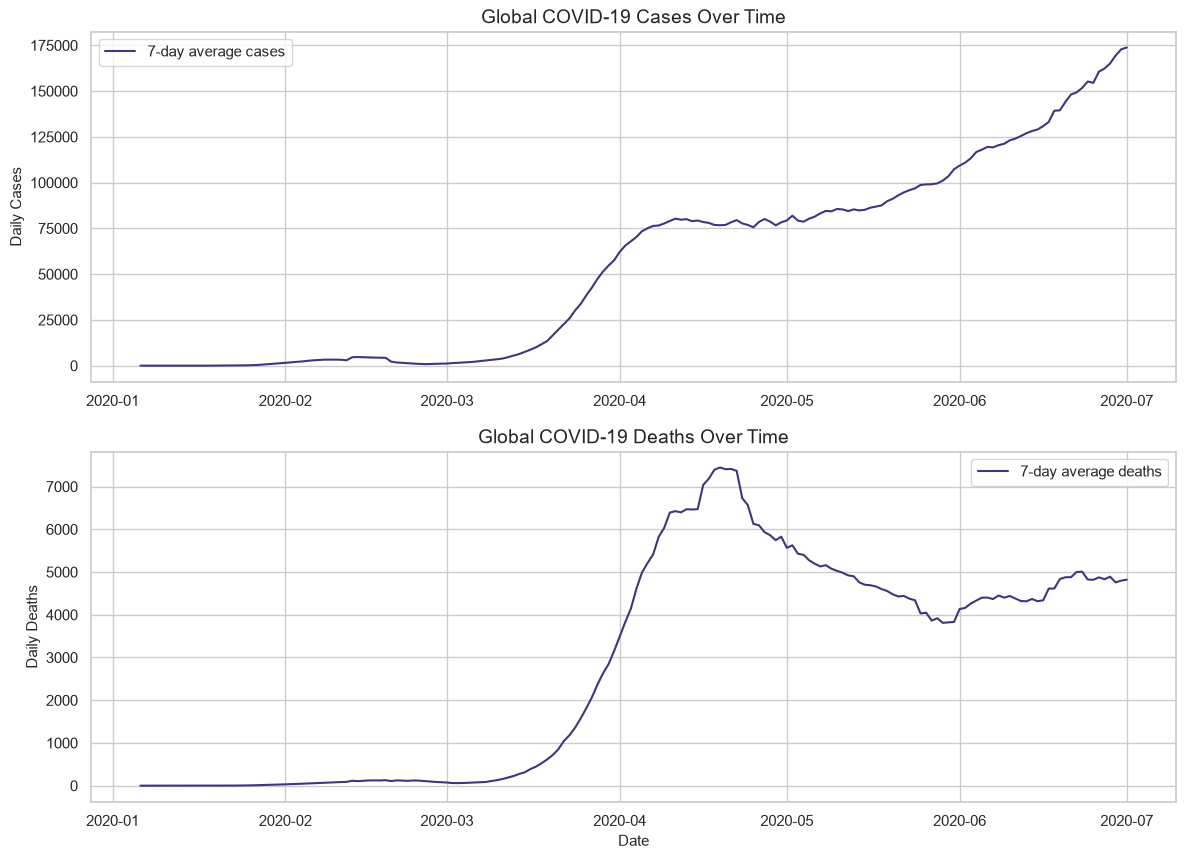

In [15]:
global_trend = (
    df.groupby('dateRep')
    .agg(
        daily_cases=('cases', 'sum'),
        daily_deaths=('deaths', 'sum')
    )
    .reset_index()
    .sort_values('dateRep')
)

# Calculate 7-day moving averages
global_trend['cases_7day_avg'] = (
    global_trend['daily_cases']
    .rolling(7)
    .mean()
)

global_trend['deaths_7day_avg'] = (
    global_trend['daily_deaths']
    .rolling(7)
    .mean()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Cases
axes[0].plot(
    global_trend['dateRep'],
    global_trend['cases_7day_avg'],
    label='7-day average cases'
)

axes[0].set_title('Global COVID-19 Cases Over Time')
axes[0].set_ylabel('Daily Cases')
axes[0].legend()

# Deaths
axes[1].plot(
    global_trend['dateRep'],
    global_trend['deaths_7day_avg'],
    label='7-day average deaths'
)

axes[1].set_title('Global COVID-19 Deaths Over Time')
axes[1].set_ylabel('Daily Deaths')
axes[1].set_xlabel('Date')
axes[1].legend()

# plt.show()

# Save the figure
plt.savefig(
    'Global COVID-19 Deaths Over Time.png',
    dpi=200,
    bbox_inches='tight',
    transparent=True
)

Visualization saved successfully: COVID_Visualizations\reported_infection_rate_vs_population_adjusted__death_rate.png


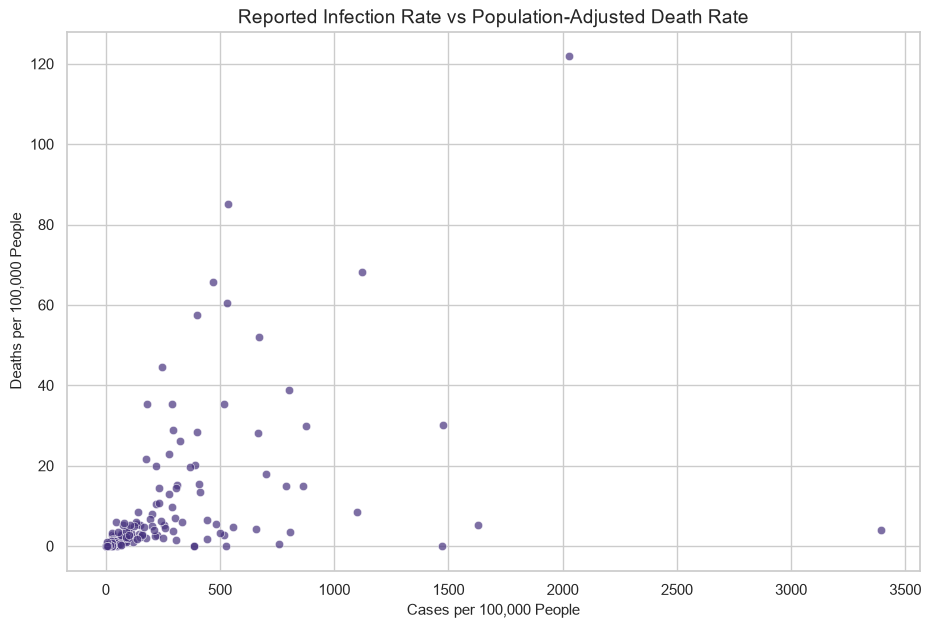

In [30]:
# Country-level population-adjusted metrics

country_data['cases_per_100k'] = (
    country_data['total_cases'] /
    country_data['population']
) * 100000

country_data['deaths_per_100k'] = (
    country_data['total_deaths'] /
    country_data['population']
) * 100000

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=country_data,
    x='cases_per_100k',
    y='deaths_per_100k',
    alpha=0.7
)

plt.title(
    'Reported Infection Rate vs Population-Adjusted Death Rate'
)

plt.xlabel('Cases per 100,000 People')
plt.ylabel('Deaths per 100,000 People')

save_visualization(fig, 'reported_infection_rate_vs_population_adjusted__death_rate')

plt.show()
plt.close(fig)

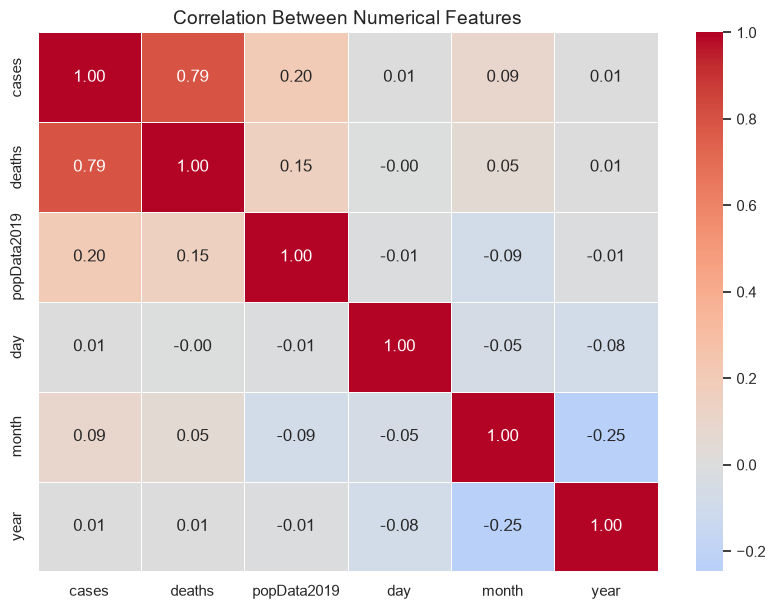

In [16]:
correlation_columns = [
    'cases',
    'deaths',
    'popData2019',
    'day',
    'month',
    'year'
]

correlation_matrix = df[
    correlation_columns
].corr(method='pearson')

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Between Numerical Features')

# plt.show()

# Save the figure
plt.savefig(
    'Correlation Between Numerical Features.png',
    dpi=200,
    bbox_inches='tight',
    transparent=True
)